# 01 — Backpropagation By Hand, Then on a 2-Layer MLP

**Overview:** a tiny manual numerical example first, then full backpropagation from scratch for
the 2-layer MLP from `15_deep_learning`, with every analytic gradient checked numerically.

**Required libraries:** `numpy`, `matplotlib`.

Connects to: `15_deep_learning` (the forward pass, reused exactly) and Day 1's
`05_ml_mathematics` (the chain rule, numerical gradient checking). Leads to:
`19_pytorch_autograd` (the same math, automated).

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)


## 1. A tiny manual numerical example: forward → loss → gradient, by hand

**Setup:** `a = 2`, `b = 3`. `c = a * b` (multiply). `d = c + 1` (add). `L = d^2` (square, our
"loss"). We want `∂L/∂a` and `∂L/∂b`.

**By hand, via the chain rule:**
```
∂L/∂d = 2d
∂d/∂c = 1
∂c/∂a = b
∂c/∂b = a
∂L/∂a = ∂L/∂d · ∂d/∂c · ∂c/∂a = 2d · 1 · b
∂L/∂b = ∂L/∂d · ∂d/∂c · ∂c/∂b = 2d · 1 · a
```

In [2]:
a, b = 2.0, 3.0

# Forward pass, caching every intermediate value (exactly what backprop needs later).
c = a * b
d = c + 1
L = d ** 2
print(f"forward: a={a}, b={b}, c={c}, d={d}, L={L}")

# Backward pass, by hand, using the chain rule derived above.
dL_dd = 2 * d
dd_dc = 1.0
dc_da = b
dc_db = a

dL_da = dL_dd * dd_dc * dc_da
dL_db = dL_dd * dd_dc * dc_db
print(f"\nhand-derived gradients: dL/da={dL_da}, dL/db={dL_db}")

# Verify against numerical (finite-difference) gradients.
def L_of(a_val, b_val):
    return ((a_val * b_val) + 1) ** 2

h = 1e-6
numerical_dL_da = (L_of(a + h, b) - L_of(a - h, b)) / (2 * h)
numerical_dL_db = (L_of(a, b + h) - L_of(a, b - h)) / (2 * h)
print(f"numerical gradients:    dL/da={numerical_dL_da:.4f}, dL/db={numerical_dL_db:.4f}")

assert abs(dL_da - numerical_dL_da) < 1e-3
assert abs(dL_db - numerical_dL_db) < 1e-3
print("\nhand-derived gradients match numerical gradients.")


forward: a=2.0, b=3.0, c=6.0, d=7.0, L=49.0

hand-derived gradients: dL/da=42.0, dL/db=28.0
numerical gradients:    dL/da=42.0000, dL/db=28.0000

hand-derived gradients match numerical gradients.


## 2. The full training step, as a diagram in code

```text
forward pass -> prediction -> loss -> gradients (backward pass) -> optimizer -> updated weights
```

We now apply exactly this to the 2-layer MLP from `15_deep_learning`.

## 3. Forward pass (caching intermediates) for the 2-layer MLP

In [3]:
def relu(z):
    return np.maximum(0, z)

def relu_backward(dA, Z):
    """dL/dZ given dL/dA and the cached pre-activation Z."""
    return dA * (Z > 0)

def softmax(z):
    z_shifted = z - np.max(z, axis=-1, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=-1, keepdims=True)

def cross_entropy_loss(probs, true_class_indices, eps=1e-12):
    n = len(true_class_indices)
    p_true = np.clip(probs[np.arange(n), true_class_indices], eps, 1.0)
    return -np.mean(np.log(p_true))

batch_size, in_features, hidden_units, out_classes = 16, 5, 8, 3
X = rng.normal(size=(batch_size, in_features))
y_true = rng.integers(0, out_classes, size=batch_size)

W1 = rng.normal(scale=0.3, size=(in_features, hidden_units))
b1 = np.zeros(hidden_units)
W2 = rng.normal(scale=0.3, size=(hidden_units, out_classes))
b2 = np.zeros(out_classes)

def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)
    Z2 = A1 @ W2 + b2
    probs = softmax(Z2)
    cache = (X, Z1, A1, Z2, probs)
    return probs, cache

probs, cache = forward(X, W1, b1, W2, b2)
loss = cross_entropy_loss(probs, y_true)
print("forward pass output shape:", probs.shape, "loss:", round(loss, 4))


forward pass output shape: (16, 3) loss: 1.1217


## 4. Backward pass, by hand, using cached forward values

**Key gradients** (softmax + cross-entropy combine into a famously clean gradient):
`dZ2 = probs - one_hot(y_true)`, then ordinary chain rule backward through each linear layer.

In [4]:
def backward(cache, y_true, W2):
    X, Z1, A1, Z2, probs = cache
    n = X.shape[0]

    one_hot = np.zeros_like(probs)
    one_hot[np.arange(n), y_true] = 1.0
    dZ2 = (probs - one_hot) / n          # softmax+cross-entropy's combined gradient, averaged over batch

    dW2 = A1.T @ dZ2                      # (hidden_units, out_classes)
    db2 = dZ2.sum(axis=0)                 # (out_classes,)

    dA1 = dZ2 @ W2.T                      # (batch, hidden_units) -- gradient flows back through W2
    dZ1 = relu_backward(dA1, Z1)          # (batch, hidden_units)

    dW1 = X.T @ dZ1                       # (in_features, hidden_units)
    db1 = dZ1.sum(axis=0)                 # (hidden_units,)

    return dW1, db1, dW2, db2

dW1, db1, dW2, db2 = backward(cache, y_true, W2)
print("dW1 shape:", dW1.shape, "== W1 shape:", W1.shape)
print("dW2 shape:", dW2.shape, "== W2 shape:", W2.shape)

assert dW1.shape == W1.shape
assert db1.shape == b1.shape
assert dW2.shape == W2.shape
assert db2.shape == b2.shape


dW1 shape: (5, 8) == W1 shape: (5, 8)
dW2 shape: (8, 3) == W2 shape: (8, 3)


## 5. Numerical gradient checking: verify EVERY analytic gradient

⚠️ **Common Mistake:** trusting a hand-written backward pass without checking it numerically --
a transpose bug can silently produce plausible-looking but wrong gradients.

In [5]:
def loss_given_params(W1, b1, W2, b2):
    probs, _ = forward(X, W1, b1, W2, b2)
    return cross_entropy_loss(probs, y_true)

def numerical_gradient(param, loss_fn_of_param, h=1e-5):
    grad = np.zeros_like(param)
    it = np.nditer(param, flags=["multi_index"])
    for _ in it:
        idx = it.multi_index
        original = param[idx]
        param[idx] = original + h
        loss_plus = loss_fn_of_param()
        param[idx] = original - h
        loss_minus = loss_fn_of_param()
        param[idx] = original
        grad[idx] = (loss_plus - loss_minus) / (2 * h)
    return grad

# Checking every element of W1 and W2 is slow in pure Python -- check a random sample of
# entries from each, which is standard practice for gradient-check sanity testing.
def sample_check(param, analytic_grad, loss_fn, name, n_samples=10):
    flat_idx = rng.choice(param.size, size=min(n_samples, param.size), replace=False)
    max_rel_error = 0.0
    for flat_i in flat_idx:
        idx = np.unravel_index(flat_i, param.shape)
        original = param[idx]
        param[idx] = original + 1e-5
        loss_plus = loss_fn()
        param[idx] = original - 1e-5
        loss_minus = loss_fn()
        param[idx] = original
        numeric = (loss_plus - loss_minus) / (2e-5)
        analytic = analytic_grad[idx]
        rel_error = abs(numeric - analytic) / (abs(numeric) + abs(analytic) + 1e-8)
        max_rel_error = max(max_rel_error, rel_error)
    print(f"{name}: max relative error over {len(flat_idx)} sampled entries = {max_rel_error:.2e}")
    return max_rel_error

err_w1 = sample_check(W1, dW1, lambda: loss_given_params(W1, b1, W2, b2), "dW1")
err_w2 = sample_check(W2, dW2, lambda: loss_given_params(W1, b1, W2, b2), "dW2")
err_b1 = sample_check(b1, db1, lambda: loss_given_params(W1, b1, W2, b2), "db1")
err_b2 = sample_check(b2, db2, lambda: loss_given_params(W1, b1, W2, b2), "db2")

assert max(err_w1, err_w2, err_b1, err_b2) < 1e-4
print("\nall analytic gradients match numerical gradients -- the backward pass is correct.")


dW1: max relative error over 10 sampled entries = 7.88e-10
dW2: max relative error over 10 sampled entries = 2.65e-08
db1: max relative error over 8 sampled entries = 3.02e-09
db2: max relative error over 3 sampled entries = 6.65e-09

all analytic gradients match numerical gradients -- the backward pass is correct.


## 6. A full training step: forward → loss → backward → optimizer update

loss before training: 1.1217
loss after 100 steps: 0.0447


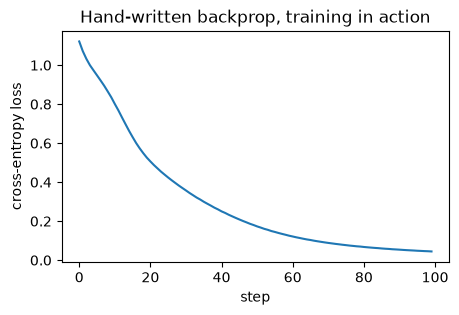

In [6]:
lr = 0.5
losses = []
for step in range(100):
    probs, cache = forward(X, W1, b1, W2, b2)
    loss = cross_entropy_loss(probs, y_true)
    losses.append(loss)

    dW1, db1, dW2, db2 = backward(cache, y_true, W2)

    # Plain SGD update (any Day 2 optimizer could be substituted here).
    W1 -= lr * dW1; b1 -= lr * db1
    W2 -= lr * dW2; b2 -= lr * db2

print("loss before training:", round(losses[0], 4))
print("loss after 100 steps:", round(losses[-1], 4))
assert losses[-1] < losses[0]

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(losses)
ax.set_xlabel("step"); ax.set_ylabel("cross-entropy loss"); ax.set_title("Hand-written backprop, training in action")
plt.show()


## 7. Connection to what's next

`19_pytorch_autograd` recomputes exactly this gradient computation, but automatically — you'll
build the same 2-layer MLP in PyTorch and compare `loss.backward()`'s gradients against the
hand-derived ones from this notebook.

## 8. Interview questions
1. Walk through the chain rule derivation for `dW2` in this notebook's backward pass.
2. Why does the softmax+cross-entropy combination simplify to `probs - one_hot(y_true)`?
3. What's the purpose of caching `Z1`, `A1`, `Z2` during the forward pass?
4. Why does ReLU's backward pass use the cached pre-activation `Z1` rather than the output `A1`?
5. Why is a numerical gradient check considered a sufficient (if slow) way to validate a hand-written backward pass?

## 9. Exercises
1. Add a third layer to the MLP and derive (then implement) its backward pass.
2. Replace ReLU with tanh in the hidden layer and derive tanh's backward pass (`dZ = dA * (1 - tanh(Z)^2)`).
3. Deliberately swap `A1.T @ dZ2` for `dZ2.T @ A1` (a transpose bug) and observe how the numerical gradient check catches it.

## 10. Summary

✅ Backpropagation is the chain rule, applied layer by layer, reusing cached forward-pass
values — exactly verified here against numerical gradients. Next: `17_deep_learning_architectures`.